<a href="https://colab.research.google.com/github/9ecolla/MA-Big-Data-Analytics/blob/main/Akhmetov_Ruslan_gradient_descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа. Градиентный спуск

На всякий случай напомним, что использование открытых источников (medium, towardsdatascience и т. д.) разрешено только при указании ссылки первоисточника. Вполне вероятно, что более одного человека нагуглят одинаковый код. Указание ссылки позволит нам не помечать такие работы как списывание.

Правила использования моделей по типу Copilot/ChatGPT и их аналогов: не более 20% кода и полное указание промпта для модели. Если просили модель что-то корректировать, или же сами что-то правили -- всё нужно указывать.

## Часть 1. Библиотека NumPy

### О задании

В данном домашнем задании вы попрактикуетесь в работе с библиотекой numpy!

In [1]:
import numpy as np

Во всех задачах необходимо написать код решения внутри функции и проверить его работу, вызвав функцию для данных из условия.

При решении задач запрещается использовать циклы (`for`, `while`) и оператор `if`.

Везде, где встречаются массивы или матрицы, подразумевается, что это `numpy.array`.

### Задание 1

Напишите функцию, возвращающую округленную взвешенную сумму оценок по данным оценкам и весам. Можете посчитать свою оценку за курс :)

In [2]:
def result_mark(weights, marks):
    return np.round(np.dot(weights, marks))

In [3]:
weights = np.array([0.35, 0.4, 0.15, 0.1])
marks = np.array([6, 9, 8, 7])
result_mark(weights, marks)

np.float64(8.0)

### Задание 2

Напишите функцию, меняющую каждое третье (начиная с 0) значение массива целых чисел на заданное число. Например, если на вход поступает массив `array([3, 5, 1, 0, -3, 22, 213436])` и число `-111`, то на выходе должен получиться массив `array([-111, 5, 1, -111, -3, 22, -111])`.

In [4]:
def change_array(array, number):
    array = array.copy()
    array[::3] = number
    return array

In [5]:
array = np.array([3, 5, 1, 0, -3, 22, 213436])
number = -111
change_array(array, number)

array([-111,    5,    1, -111,   -3,   22, -111])

### Задание 3

Напишите функцию, выдающую индексы «близких» элементов заданных массивов, а именно тех пар элементов, чей модуль разницы не превосходит заданного значения. Например, если на вход поступают массив `array([1.5, 0.5, 2, -4.1, -3, 6, -1])`, массив `array([1.2, 0.5, 1, -4, 3, 0, -1.2])` и число `0.5`, то на выходе должен получиться массив `array([0, 1, 3, 6])` (_**важно: не `tuple`, а одномерный массив типа `numpy.ndarray` (то есть `.ndim` от него равно 1)!**_).

In [6]:
def find_close(array1, array2, precision):
    return np.where(np.abs(array1 - array2) <= precision)[0]

In [7]:
array1 = np.array([1.5, 0.5, 2, -4.1, -3, 6, -1])
array2 = np.array([1.2, 0.5, 1, -4, 3, 0, -1.2])
precision = 0.5
find_close(array1, array2, precision)

array([0, 1, 3, 6])

### Задание 4

Напишите функцию, которая составляет блочную матрицу из четырех блоков, где каждый блок - это заданная матрица. Например, если на вход поступает матрица
$$
\begin{pmatrix}
0 & 1 & 2\\
3 & 4 & 5\\
\end{pmatrix},
$$
то ответом будет матрица
$$
\begin{pmatrix}
0 & 1 & 2 & 0 & 1 & 2\\
3 & 4 & 5 & 3 & 4 & 5\\
0 & 1 & 2 & 0 & 1 & 2\\
3 & 4 & 5 & 3 & 4 & 5\\
\end{pmatrix}
$$

In [8]:
def block_matrix(block):
    return np.block([[block, block],
                     [block, block]])

In [9]:
block = np.array([[0, 1, 2], [3, 4, 5]])
block_matrix(block)

array([[0, 1, 2, 0, 1, 2],
       [3, 4, 5, 3, 4, 5],
       [0, 1, 2, 0, 1, 2],
       [3, 4, 5, 3, 4, 5]])

### Задание 5

Напишите функцию, вычисляющую произведение всех ненулевых диагональных элементов на диагонали данной квадратной матрицы. Например, если на вход поступает матрица
$$
\begin{pmatrix}
0 & 1 & 2\\
3 & 4 & 5\\
6 & 7 & 8\\
\end{pmatrix},
$$
то ответом будет 32.

In [10]:
def diag_prod(matrix):
    diagonal = np.diag(matrix)
    return np.prod(diagonal[diagonal != 0])

In [11]:
matrix = np.array([[0, 1, 2], [3, 4, 5], [6, 7, 8]])
diag_prod(matrix)

np.int64(32)

### Задание 6

Для улучшения качества работы некоторых алгоритмов машинного обучения может быть полезно использовать [нормализацию данных](https://vk.cc/8xmfQk), чтобы привести признаки в выборке к одному масштабу — а именно, из каждого столбца вычесть среднее его значений и поделить на их стандартное отклонение. Напишите функцию, нормализующую входящую матрицу (по столбцам). Например, если на вход подается матрица
$$
\begin{pmatrix}
1 & 4 & 4200\\
0 & 10 & 5000\\
1 & 2 & 1000\\
\end{pmatrix},
$$
то результатом с точностью до сотых будет матрица
$$
\begin{pmatrix}
0.71 & -0.39 & 0.46\\
-1.41 & 1.37 & 0.93\\
0.71 & -0.98 & -1.39\\
\end{pmatrix}
$$

_Подсказка. Учтите, что в вашей матрице не должно получаться никаких nan. Подумайте, в каком случае они могут возникнуть и как обойти эту проблему._


In [12]:
def normalize(matrix):
    mean = np.mean(matrix, axis=0)
    std = np.std(matrix, axis=0)
    std[std == 0] = 1
    return (matrix - mean) / std

In [13]:
matrix = np.array([[1, 4, 4200], [0, 10, 5000], [1, 2, 1000]])
normalize(matrix)

array([[ 0.70710678, -0.39223227,  0.46291005],
       [-1.41421356,  1.37281295,  0.9258201 ],
       [ 0.70710678, -0.98058068, -1.38873015]])

### Задание 7

Напишите функцию, вычисляющую какую-нибудь первообразную данного полинома (в качестве константы возьмите ваше любимое число). Например, если на вход поступает массив коэффициентов `array([4, 6, 0, 1])`, что соответствует полиному $4x^3 + 6x^2 + 1$, на выходе получается массив коэффициентов `array([1, 2, 0, 1, -2])`, соответствующий полиному $x^4 + 2x^3 + x - 2$.

In [14]:
def antiderivative(coefs):
    return np.polyint(coefs, k=777)

In [15]:
coefs = np.array([4, 6, 0, 1])
antiderivative(coefs)

array([  1.,   2.,   0.,   1., 777.])

### Задание 8

Напишите функцию, делающую данную [треугольную матрицу](https://ru.wikipedia.org/wiki/%D0%A2%D1%80%D0%B5%D1%83%D0%B3%D0%BE%D0%BB%D1%8C%D0%BD%D0%B0%D1%8F_%D0%BC%D0%B0%D1%82%D1%80%D0%B8%D1%86%D0%B0) симметричной. Например, если на вход поступает матрица
$$
\begin{pmatrix}
1 & 2 & 3 & 4\\
0 & 5 & 6 & 7\\
0 & 0 & 8 & 9\\
0 & 0 & 0 & 10\\
\end{pmatrix},
$$
то на выходе должна быть матрица
$$
\begin{pmatrix}
1 & 2 & 3 & 4\\
2 & 5 & 6 & 7\\
3 & 6 & 8 & 9\\
4 & 7 & 9 & 10\\
\end{pmatrix}.
$$

In [16]:
def make_symmetric(matrix):
    return matrix + matrix.T - np.diag(np.diag(matrix))

In [17]:
matrix = np.array([[1, 2, 3, 4], [0, 5, 6, 7], [0, 0, 8, 9], [0, 0, 0, 10]])
make_symmetric(matrix)

array([[ 1,  2,  3,  4],
       [ 2,  5,  6,  7],
       [ 3,  6,  8,  9],
       [ 4,  7,  9, 10]])

### Задание 9

Напишите функцию, создающую прямоугольную матрицу из m одинаковых строк, заполненных последовательными натуральными числами от a до b включительно в возрастающем порядке. Например, если m = 5, a = 3, b = 10, то на выходе будет матрица
$$
\begin{pmatrix}
3 & 4 & 5 & 6 & 7 & 8 & 9 & 10\\
3 & 4 & 5 & 6 & 7 & 8 & 9 & 10\\
3 & 4 & 5 & 6 & 7 & 8 & 9 & 10\\
3 & 4 & 5 & 6 & 7 & 8 & 9 & 10\\
3 & 4 & 5 & 6 & 7 & 8 & 9 & 10\\
\end{pmatrix}
$$

In [18]:
def construct_matrix(m, a, b):
    return np.tile(np.arange(a, b + 1), (m, 1))

In [19]:
m = 5
a = 3
b = 10
construct_matrix(m, a, b)

array([[ 3,  4,  5,  6,  7,  8,  9, 10],
       [ 3,  4,  5,  6,  7,  8,  9, 10],
       [ 3,  4,  5,  6,  7,  8,  9, 10],
       [ 3,  4,  5,  6,  7,  8,  9, 10],
       [ 3,  4,  5,  6,  7,  8,  9, 10]])

### Задание 10

Напишите функцию, вычисляющую [косинусную близость](https://en.wikipedia.org/wiki/Cosine_similarity) двух векторов. Например, если на вход поступают вектора `array([-2, 1, 0, -5, 4, 3, -3])` и `array([0, 2, -2, 10, 6, 0, 0])`, ответом будет -0.25.

In [20]:
def cosine_similarity(vec1, vec2):
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

In [21]:
vec1 = np.array([-2, 1, 0, -5, 4, 3, -3])
vec2 = np.array([0, 2, -2, 10, 6, 0, 0])
cosine_similarity(vec1, vec2)

np.float64(-0.25)

## Часть 2. Градиентный спуск

Имеем 1000 объектов и 10 признаков у каждого (+таргет)!

Обучим модель линейной регрессии:

$$
a(x) = \beta_1 d_{1} + \beta_2 d_{2} + \beta_3 d_{3} + \beta_4 d_{4} + \beta_5 d_{5} + \beta_6 d_{6} + \beta_7 d_{7} + \beta_8 d_{8} + \beta_9 d_{9} + \beta_{10} d_{10} + \beta_0
$$

Которая минимизирует MSE:

$$
Q(a(X), Y) = \sum_i^{1000} (a(x_i) - y_i)^2
$$

In [22]:
import pandas as pd
data = pd.read_csv('https://www.dropbox.com/scl/fi/kn9ow3wg470op7svd4j4f/gd_practice_data.csv?rlkey=bods94fgcndn6vuydsm0bao7v&st=ei4otwq6&dl=1')

data.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,target
0,0.113768,0.930064,0.330528,0.010987,0.265703,0.699462,0.058465,0.431643,0.650958,0.751820,30.147094
1,0.380048,0.485946,0.870232,0.473401,0.454516,0.500864,0.471723,0.234329,0.072982,0.008372,21.424402
2,0.768462,0.217706,0.727438,0.718377,0.452155,0.434638,0.043989,0.972489,0.450133,0.378157,31.422056
3,0.606637,0.604335,0.540332,0.491236,0.325632,0.206348,0.825767,0.332475,0.955518,0.162811,31.308588
4,0.119770,0.469718,0.632829,0.504207,0.238259,0.452457,0.775360,0.174262,0.117621,0.218883,23.322751


In [23]:
data.describe().T # выводим описательные статистики

,count,mean,std,min,25%,50%,75%,max
feature_1,1000.0,0.517324,0.287517,0.000666,0.276309,0.522711,0.763972,0.999786
feature_2,1000.0,0.504317,0.292191,0.002137,0.239439,0.506636,0.760484,0.999431
feature_3,1000.0,0.474539,0.284589,0.001914,0.225862,0.469790,0.701349,0.999283
feature_4,1000.0,0.477866,0.288384,0.000553,0.226439,0.489351,0.709410,0.999438
feature_5,1000.0,0.486847,0.293399,0.000296,0.233616,0.476104,0.742801,0.999815
feature_6,1000.0,0.509389,0.286867,0.000385,0.272332,0.511387,0.745637,0.999629
feature_7,1000.0,0.495281,0.297307,0.000411,0.233966,0.496892,0.759601,0.999155
feature_8,1000.0,0.512353,0.291120,0.000500,0.252427,0.532131,0.767321,0.997396
feature_9,1000.0,0.489876,0.290901,0.000433,0.239756,0.487143,0.742749,0.999661
feature_10,1000.0,0.493783,0.288601,0.000029,0.248617,0.489517,0.736359,0.998055


Обучим коэффициенты линейной регрессии с помощью библиотеки <a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html"> **sklearn** </a>

Отдельно выведем оценку свободного коэффициента  ($\beta_0$ при $d_0 = 1$)

In [24]:
from sklearn.linear_model import LinearRegression
X = data.drop('target', axis=1)
Y = data.target

model = LinearRegression()
model.fit(X, Y)

LinearRegression()

Посмотрим на веса модели:

In [25]:
model.coef_

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

In [26]:
model.intercept_

np.float64(4.37315703870712)

Теперь вам необходимо реализовать функции для оптимизации коэффициентов линейной регрессии МНК.
Подразумевается, что на вход алгоритм будет принимать следующие параметры:

- 2 pandas датафрейма **samples** и **targets**, содержащих матрицу объектов и ветор ответов соответственно
- значение **learning rate**, который корректирует длину вектора-градиента (чтобы он не взорвался)
- значение **threshold**'а для критерия останова (когда мы считаем, что мы сошлись к оптимуму)
- значение **max_iter**, ограничивающее количество итераций градиентного спуска

Ниже есть следующие заготовки функций, которые надо дополнить:

- **add_constant_feature**: добавляет колонку с названием *constant* из единичек к переданному датафрейму **samples**. Это позволяет оценить свободный коэффициент $\beta_0$.

- **calculate_mse_loss**: вычисляет при текущих весах **self.beta** значение среднеквадратической ошибки.

- **calculate_gradient**: вычисляет при текущих весах вектор-градиент по функционалу.

- **iteration**: производит итерацию градиентного спуска, то есть обновляет веса модели, в соответствии с установленным **learning_rate = $\eta$**: $\beta^{(n+1)} = \beta^{(n)} - \eta \cdot \nabla Q(\beta^{(n)})$

- **learn**: производит итерации обучения до того момента, пока не сработает критерий останова обучения. В этот раз критерием останова будет следующее событие: во время крайней итерации изменение в функционале качества модели составило значение меньшее, чем **self.threshold**. Иными словами, $|Q(\beta^{(n)}) - Q(\beta^{(n+1)})| < threshold$.

### Hint: пример вычисления производной

$$
Q(a, X) = \frac{1}{N}\cdot\sum_{i=1}^N (\beta_1 \cdot d_{i1} + ... + \beta_n \cdot d_{in} - y_i)^2
$$

Выше - минимизируемая функция. Она зависит от n переменных: $\beta_1, ..., \beta_n$. Вектор-градиент - матрица с одной строчкой, состоящей из производных 1го порядка по всем переменным.

$$
\nabla Q(a, X) = (Q'_{\beta_1} \;\;\; Q'_{\beta_2} \;\;\; ... \;\;\; Q'_{\beta_{n-1}}  \;\;\;  Q'_{\beta_n})
$$

Пример вычисления производной по первой переменной:

$$
Q'_{\beta_1} = \frac{2}{N} \cdot \sum_{i=1}^N d_{i1} (\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i)
$$

Скажем, для нашего датасета X, Y вычислим эту саму производную при начальных единичных коэффициентах $\beta_{start} = (1 \;\;\; 1 \;\;\; ...)$



Получим для каждого объекта в начале выражение из скобочек:
$$
\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i
$$

In [27]:
### Инициализируем точку для коэффициентов в виде вектора из единичек
initial_betas = np.ones(X.shape[1])

### Получим выражение выше для каждого объекта.
### Для этого скалярно перемножим строчки из X на наши beta

scalar_value = np.dot(X, initial_betas.reshape(-1, 1)).ravel()
scalar_value = (scalar_value - Y).values

Теперь полученное значение для каждого объекта умножим на соответствующее значение признака $d_1$:

$$
d_{i1} \cdot (\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i)
$$

In [28]:
### Возьмем столбик со значениями 1 признака

d_i1 = X.values[:, 0]

### Умножим каждый объект на соответствующее значение признака
scalar_value = scalar_value * d_i1

In [29]:
### Наконец, умножим все на 2 и усреднимся,
### чтобы получить значение производной по первому параметру

2 * np.mean(scalar_value)

np.float64(-27.62384887912409)

### Эта логика поможет Вам при реализации!

Также старайтесь избегать циклов там, где они не нужны. Не забыли же, что циклы медленные в питоне? :)

In [30]:
# вычисляет при текущих весах self.beta значение среднеквадратической ошибки.
def calculate_mse_loss(beta: np.ndarray, samples: np.ndarray, targets: np.ndarray) -> float:
    """
    Метод для расчета среднеквадратической ошибки.

    :return: среднеквадратическая ошибка при текущих весах модели : float
    """
    # Вычисление MSE на основе текущих весов и таргетов
    loss =  np.mean((samples @ beta - targets)**2)
    return loss

In [31]:
# добавляет колонку с названием constant из единичек к переданному датафрейму samples. Это позволяет оценить свободный коэффициент  β0
def add_constant_feature(samples: np.ndarray, beta: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Функция для создания константной фичи в матрице объектов samples.
    Добавляет колонку с единицами и обновляет вектор весов.
    """
    # А здесь мы уже всё написали для Вас :)

    # Добавление константной колонки к матрице признаков
    samples['constants'] = 1

    # Обновление вектора весов
    beta = np.append(beta, 1)

    return samples, beta

In [32]:
# вычисляет при текущих весах вектор-градиент по функционалу.
def calculate_gradient(beta: np.ndarray, samples: np.ndarray, targets: np.ndarray) -> np.ndarray:
    """
    Функция для вычисления вектора-градиента.

    :return: вектор-градиент, содержащий производные по каждому признаку : np.ndarray
    """
    # Вычисление разницы между предсказанными и фактическими значениями
    diff = samples @ beta - targets

    # Вычисление градиента (не забудьте 2 и усреднить по количеству образцов!)
    # Решение на полный балл предполагает запись в матричной форме, без циклов
    gradient =  2/samples.shape[0] * (samples.T @ diff)

    return gradient

In [33]:
#  производит итерацию градиентного спуска, то есть обновляет веса модели, в соответствии с установленным learning_rate
def iteration(beta: np.ndarray, samples: np.ndarray, targets: np.ndarray, learning_rate: float) -> np.ndarray:
    """
    Обновляем веса модели в соответствии с текущим вектором-градиентом.
    """
    # Обновление весов на основе вычисленного градиента
    gradient = calculate_gradient(beta, samples, targets)

    # Обновите веса модели используя градиент выше. Не перепутайте знак :)
    new_beta = beta - learning_rate * gradient

    return new_beta

In [34]:
# производит итерации обучения до того момента, пока не сработает критерий останова обучения.
def learn(samples: pd.DataFrame, targets: pd.DataFrame,
                learning_rate: float = 1e-3, threshold: float=1e-6, max_iter: int = 100000) -> tuple[np.ndarray, int, dict]:
    """
    Итеративное обучение весов модели до срабатывания критерия останова.

    Запись mse и номера итерации в iteration_loss_dict.
    """

    # Сохранение матрицы признаков и таргетов
    samples = samples.copy()
    targets = targets.copy()

    # Инициализация весов
    beta = np.ones(samples.shape[1])

    # Добавим константу и перейдем к numpy
    samples, beta = add_constant_feature(samples, beta)
    samples = np.array(samples)

    # Преобразование таргетов в одномерный массив
    targets = targets.values.reshape(-1)

    # Инициализация словаря для хранения MSE
    iteration_loss_dict = {0 : calculate_mse_loss(beta, samples, targets)}

    for itera in range(1, max_iter+1):
        start_betas = beta.copy()  # Фиксируем текущие веса

        # Выполняем шаг градиентного спуска при помощи iteration
        new_beta = iteration(start_betas, samples, targets, learning_rate)

        # Рассчитываем новую MSE
        new_mse = calculate_mse_loss(new_beta, samples, targets)

        # Записываем MSE и номер итерации
        iteration_loss_dict[itera] = new_mse

        # Проверяем условие остановки по изменению MSE
        if abs(new_mse - iteration_loss_dict[itera-1]) < threshold:
          beta = new_beta
          break

        # Обновляем предыдущее значение весов
        beta = new_beta

        # Выводим MSE в реальном времени
        print("MSE:", new_mse, "                   ", end="\r")

    if itera == max_iter:
        print("Кажется алгоритм расходится. Возможно, у Вас где-то ошибка :(")

    return beta, itera, iteration_loss_dict

Обучим коэффициенты линейной модели с помощью реализованного нами градиентного спуска, не забыв добавить свободную переменную. Получились ли такие же коэффициенты, как и при использовании **LinearRegression** из **sklearn**? Если нет, то почему они отличаются, на Ваш взгляд, и сильно ли?

Последнее число соответствует свободному коэффициенту, он же **.intercept_** в **LinearRegression** из **sklearn**

In [35]:
# Запустим обучение
beta, iteration_num, iteration_loss_dict = learn(X, Y)

In [36]:
print('Веса модели при переменных d1, d2, ..., d10 равны соответственно: \n\n' + str(beta))

Веса модели при переменных d1, d2, ..., d10 равны соответственно: 

[0.88733305 1.90100713 2.88063607 3.87662612 4.89623507 5.89126182
 6.89254811 7.90311947 8.87580109 9.86109585 4.94854733]


In [37]:
model.coef_

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

In [38]:
model.intercept_

np.float64(4.37315703870712)

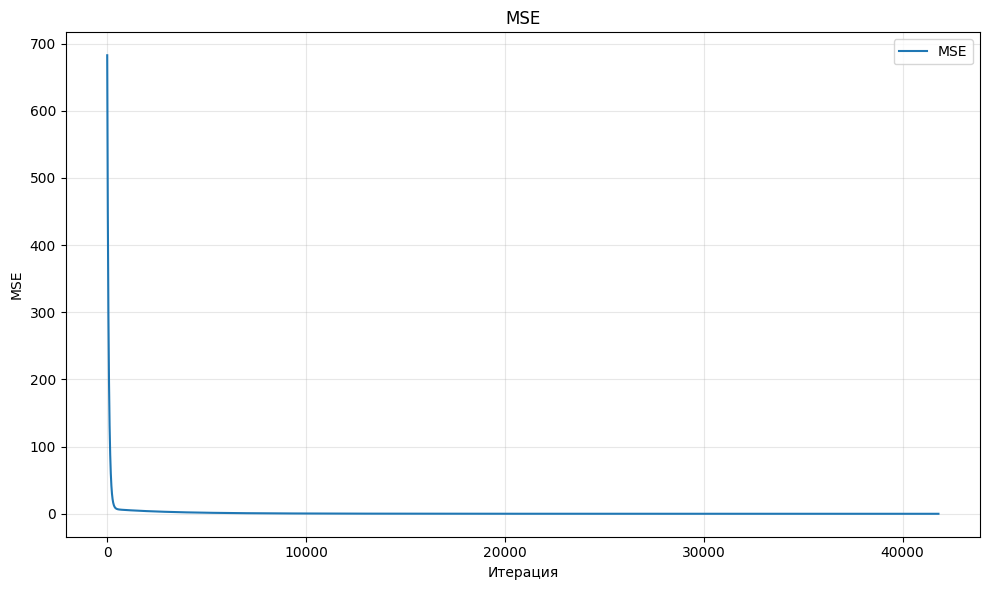

In [39]:
import matplotlib.pyplot as plt

def plot_loss(iteration_loss_dict, title="MSE"):
    iters = sorted(iteration_loss_dict.keys())
    losses = [iteration_loss_dict[i] for i in iters]

    plt.figure(figsize=(10, 6))
    plt.plot(iters, losses, linewidth=1.5, label="MSE")


    plt.xlabel("Итерация")
    plt.ylabel("MSE")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_loss(iteration_loss_dict)

Коэффициенты градиентного спуска приблизились к коэффициентам LinearRegression, но не совпали полностью. Максимальное абсолютное отличие коэффициентов при признаках составляет около 0,139. Свободный коэффициент равен примерно 4,949 вместо 4,373, отличие — около 0,575. Причина в критерии остановки. Это не гарантирует, что коэффициенты уже достаточно близки к оптимальным. При небольшом шаге обучения ошибка может изменяться медленно. Для более точного приближения можно уменьшить threshold и при необходимости увеличить max_iter.